# Project 4: Next-Word Prediction Using Word Embeddings and a Neural Language Model

**Author:** Albert Kabore, PhD Student in Artificial Intelligence, University of the Cumberlands

**GitHub:** [Project repository](https://github.com/albertokabore/Project-4-Next-Word-Prediction-Using-Word-Embeddings-and-a-Neural-Language-Model/tree/main)

**Contents:** [Introduction](#intro) | [Pseudocode](#pseudocode) | [Evaluation](#evaluation) | [Step observations](#observations-step-2) | [Final Insights and Recommendations](#insights) | [Conclusion](#conclusion)

This notebook builds a model that uses five words to predict the next word. It covers each assignment requirement with Python code and a plain-English explanation.

| Requirement | Section |
|---|---|
| Collect a dataset | [Step 1](#step1) |
| Clean the text | [Step 2](#step2) |
| Convert to lowercase | [Step 3](#step3) |
| Remove punctuation | [Step 4](#step4) |
| Tokenize | [Step 5](#step5) |
| Build a vocabulary | [Step 6](#step6) |
| Generate training sequences | [Step 7](#step7) |
| Convert words to vectors with Word2Vec | [Step 8](#step8) |
| Train a neural network | [Step 9](#step9) |
| Evaluate performance | [Evaluation](#evaluation) |

Functions live in the `nwp/` package. Calls to `show(...)` display their source code when run. Start from the project folder after installing `requirements.txt` and Jupyter.

Run the cells in order to generate outputs and save the trained model.


<a id="intro"></a>
## Introduction

Next-word prediction means estimating which word is likely to follow a piece of text. Phone keyboards use this idea when they suggest words as someone types. In this project, the goal is to build a small neural language model and explain how raw text becomes training examples, word vectors and next-word predictions.

The dataset is *The Adventures of Sherlock Holmes*, from Kaggle. The pipeline cleans the text, converts it to lowercase, removes punctuation with an exception for apostrophes inside words, and splits the text into tokens. It then builds a vocabulary and creates examples in which five context words are used to predict the next word.

Word2Vec learns a 100-dimensional vector for each retained word from the training text. These vectors initialize an embedding layer, and an LSTM neural network learns to use them to predict the next word. The vocabulary, Word2Vec model and neural-network weights are learned from the training split. A separate validation split selects the checkpoint, and the final held-out split is used for testing.

The project demonstrates all nine assignment steps with Python code, pseudocode and plain-English explanations. Its reported test scores apply to known-word targets only; the evaluation section explains the excluded words and their effect on accuracy.


<a id="pseudocode"></a>
## Pipeline overview (pseudocode)

```text
1. COLLECT A DATASET
   If data/raw/1661-0.txt is missing:
       download Kaggle dataset "ronikdedhia/next-word-prediction"
       copy 1661-0.txt into data/raw/
   raw_text = read the file as UTF-8

2. CLEAN THE TEXT
   Remove text outside the Gutenberg START and END markers, when present
   Normalize curly quotes, dashes and accented characters to ASCII
   Split at sentence-ending punctuation followed by whitespace, and blank lines

3-5. LOWERCASE, REMOVE PUNCTUATION, TOKENIZE
   For each text segment:
       convert to lowercase
       replace punctuation with spaces, except apostrophes inside words
       collapse whitespace and split into word tokens
       discard empty token lists

   Split the segments in reading order:
       first 80% for training, next 10% for validation, remainder for testing

6. BUILD A VOCABULARY
   Count words in the training split only
   Keep words seen at least twice, ordered by frequency, then alphabetically
   Add <pad> with id 0 and <unk> with id 1
   Assign an integer id to each retained word
   Map other words to <unk>

7. GENERATE TRAINING SEQUENCES
   For each split separately:
       stream = five <pad> ids followed by all word ids in that split
       For each target position:
           input = the previous five ids
           target = the id at this position
           keep this example only if its target is not <unk>
   Record how many targets were excluded in each split

8. CONVERT WORDS TO VECTORS WITH WORD2VEC
   Train skip-gram Word2Vec on training segments only:
       100 dimensions, maximum window 5, 10 negative samples, 30 epochs
   Build a matrix with one row per vocabulary entry:
       ordinary word -> its learned vector
       <pad> -> zeros
       <unk> -> mean learned vector

9. TRAIN A NEURAL NETWORK
   Model = embedding lookup initialized with that matrix
           -> two LSTM layers with 256 hidden units each
           -> dropout -> linear layer with one score per vocabulary entry
   Use AdamW with learning rate 0.002 and cross-entropy loss
   For up to 20 epochs:
       keep embeddings frozen for epochs 1-2; then allow them to change
       shuffle training examples into batches of 256
       compute scores and loss; backpropagate
       clip gradient norm to 1.0 and update weights
       measure validation loss and accuracy
       reduce learning rate when validation loss stalls
       retain weights with the lowest validation loss
       stop after three epochs without improvement
   Restore the retained weights

EVALUATE
   Measure test cross-entropy, perplexity, top-1 accuracy and top-5 accuracy
   Compare accuracy with a predictor that always guesses common training words
   Report that these scores cover known-word targets only
```


In [1]:
import inspect
import logging
import random
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display
from torch.utils.data import DataLoader

from nwp.config import Config
from nwp import data, preprocess, vocab as vocab_mod, sequences, embeddings, model as model_mod, trainer
from nwp.predict import Predictor

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
logging.getLogger("gensim").setLevel(logging.WARNING)

def show(*objs):
    """Display the source code of a function or class from the nwp package."""
    for obj in objs:
        display(Markdown(f"```python\n{inspect.getsource(obj)}```"))

cfg = Config()
random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print({k: v for k, v in cfg.to_dict().items() if k not in ("data_dir", "artifacts_dir")})

Device: cpu
{'kaggle_dataset': 'ronikdedhia/next-word-prediction', 'raw_filename': '1661-0.txt', 'train_frac': 0.8, 'val_frac': 0.1, 'min_freq': 2, 'context_size': 5, 'embedding_dim': 100, 'w2v_window': 5, 'w2v_sg': 1, 'w2v_negative': 10, 'w2v_epochs': 30, 'freeze_embeddings_epochs': 2, 'hidden_size': 256, 'num_layers': 2, 'dropout': 0.3, 'batch_size': 256, 'epochs': 20, 'learning_rate': 0.002, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'patience': 3, 'seed': 42, 'device': 'auto'}


<a id="step1"></a>
## Step 1: Collect a dataset



In [2]:
show(data.collect_dataset)
raw_path = data.collect_dataset(cfg.kaggle_dataset, cfg.raw_filename, cfg.data_dir)
raw_text = data.read_text(raw_path)
print(f"File: {raw_path}")
print(f"{len(raw_text):,} characters, {len(raw_text.split()):,} whitespace-separated words")
print("-" * 60)
print(raw_text[:700])

```python
def collect_dataset(dataset: str, filename: str, data_dir: Path) -> Path:
    """Return the path to the raw text file, downloading it from Kaggle if needed.

    The file is copied into ``data_dir/raw`` so later runs work offline.
    """
    target = Path(data_dir) / "raw" / filename
    if target.exists():
        log.info("Using cached dataset at %s", target)
        return target

    import kagglehub  # imported lazily so the rest of the package works without it

    log.info("Downloading Kaggle dataset %s", dataset)
    download_dir = Path(kagglehub.dataset_download(dataset))
    source = download_dir / filename
    if not source.exists():
        found = sorted(p.name for p in download_dir.iterdir())
        raise FileNotFoundError(f"{filename!r} not in Kaggle download; found {found}")

    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(source, target)
    log.info("Saved dataset to %s", target)
    return target
```

Using cached dataset at data\raw\1661-0.txt


File: data\raw\1661-0.txt
581,887 characters, 107,602 whitespace-separated words
------------------------------------------------------------

Project Gutenberg's The Adventures of Sherlock Holmes, by Arthur Conan Doyle

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.net


Title: The Adventures of Sherlock Holmes

Author: Arthur Conan Doyle

Release Date: November 29, 2002 [EBook #1661]
Last Updated: May 20, 2019

Language: English

Character set encoding: UTF-8

*** START OF THIS PROJECT GUTENBERG EBOOK THE ADVENTURES OF SHERLOCK HOLMES ***



Produced by an anonymous Project Gutenberg volunteer and Jose Menendez



cover



The Advent


<a id="step2"></a>
## Step 2: Clean the text



In [3]:
show(preprocess.strip_gutenberg_boilerplate, preprocess.clean_text)
cleaned = preprocess.clean_text(raw_text)
print(f"Characters before cleaning: {len(raw_text):,}   after: {len(cleaned):,}")
print("Only ASCII left:", cleaned.isascii())
raw_sentences = preprocess.split_sentences(cleaned)
print(f"Sentences: {len(raw_sentences):,}")
sample = raw_sentences[40:44]
for s in sample:
    print("  •", " ".join(s.split()))

```python
def strip_gutenberg_boilerplate(text: str) -> str:
    """Keep only the book itself, dropping Project Gutenberg's licence header/footer."""
    start = _GUTENBERG_START.search(text)
    if start:
        text = text[start.end():]
    end = _GUTENBERG_END.search(text)
    if end:
        text = text[: end.start()]
    return text
```

```python
def clean_text(text: str) -> str:
    """Remove boilerplate, normalise unicode and drop non-ASCII symbols."""
    text = strip_gutenberg_boilerplate(text)
    text = text.translate(_CHAR_MAP)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return text.replace("\r\n", "\n")
```

Characters before cleaning: 581,887   after: 562,328
Only ASCII left: True
Sentences: 6,989
  • His rooms were brilliantly lit, and, even as I looked up, I saw his tall, spare figure pass twice in a dark silhouette against the blind.
  • He was pacing the room swiftly, eagerly, with his head sunk upon his chest and his hands clasped behind him.
  • To me, who knew his every mood and habit, his attitude and manner told their own story.
  • He was at work again.


<a id="observations-step-2"></a>
### Observations

- Cleaning reduced the text from 581,887 to 562,328 characters. The ASCII check returned True, confirming that the cleaned text contains only ASCII characters.
- The splitter produced 6,989 segments. Title-page material still remains inside the book markers, so cleaning did not isolate story text completely.


<a id="step3"></a>
## Step 3: Convert text to lowercase



In [4]:
show(preprocess.to_lowercase)
lower = [preprocess.to_lowercase(s) for s in sample]
for before, after in zip(sample, lower):
    print("BEFORE:", " ".join(before.split()))
    print("AFTER: ", " ".join(after.split()), "\n")

```python
def to_lowercase(text: str) -> str:
    return text.lower()
```

BEFORE: His rooms were brilliantly lit, and, even as I looked up, I saw his tall, spare figure pass twice in a dark silhouette against the blind.
AFTER:  his rooms were brilliantly lit, and, even as i looked up, i saw his tall, spare figure pass twice in a dark silhouette against the blind. 

BEFORE: He was pacing the room swiftly, eagerly, with his head sunk upon his chest and his hands clasped behind him.
AFTER:  he was pacing the room swiftly, eagerly, with his head sunk upon his chest and his hands clasped behind him. 

BEFORE: To me, who knew his every mood and habit, his attitude and manner told their own story.
AFTER:  to me, who knew his every mood and habit, his attitude and manner told their own story. 

BEFORE: He was at work again.
AFTER:  he was at work again. 



<a id="observations-step-3"></a>
### Observations

- The samples show ?His? becoming ?his? and ?He? becoming ?he?; word order and punctuation remain unchanged.
- Case variants will share vocabulary entries, reducing duplicate forms. Lowercasing also changes ?I? to ?i?, so capitalization information is lost even though the sequence of words is preserved.


<a id="step4"></a>
## Step 4: Remove punctuation



In [5]:
show(preprocess.remove_punctuation)
no_punct = [preprocess.remove_punctuation(s) for s in lower]
for before, after in zip(lower, no_punct):
    print("BEFORE:", " ".join(before.split()))
    print("AFTER: ", after, "\n")
print(repr(preprocess.remove_punctuation("it's 'quite' simple, watson!")))

```python
def remove_punctuation(text: str) -> str:
    text = _NON_WORD.sub(" ", text)
    text = _STRAY_APOSTROPHE.sub(" ", text)
    return _WHITESPACE.sub(" ", text).strip()
```

BEFORE: his rooms were brilliantly lit, and, even as i looked up, i saw his tall, spare figure pass twice in a dark silhouette against the blind.
AFTER:  his rooms were brilliantly lit and even as i looked up i saw his tall spare figure pass twice in a dark silhouette against the blind 

BEFORE: he was pacing the room swiftly, eagerly, with his head sunk upon his chest and his hands clasped behind him.
AFTER:  he was pacing the room swiftly eagerly with his head sunk upon his chest and his hands clasped behind him 

BEFORE: to me, who knew his every mood and habit, his attitude and manner told their own story.
AFTER:  to me who knew his every mood and habit his attitude and manner told their own story 

BEFORE: he was at work again.
AFTER:  he was at work again 

"it's quite simple watson"


<a id="observations-step-4"></a>
### Observations

- Commas and sentence-ending periods disappear from the samples while the words remain separated, preventing punctuation from creating extra word variants.
- The example "it's 'quite' simple, watson!" becomes "it's quite simple watson". Apostrophes inside contractions are retained, while quotation apostrophes are removed; punctuation handling therefore includes an explicit exception.


<a id="step5"></a>
## Step 5: Tokenize the text



In [ ]:
show(preprocess.tokenize, preprocess.normalize_sentence, preprocess.preprocess_corpus)
for s in no_punct[:2]:
    print(preprocess.tokenize(s))

sentences_tok = preprocess.preprocess_corpus(raw_text)
n_tokens = sum(map(len, sentences_tok))
print(f"\n{len(sentences_tok):,} sentences, {n_tokens:,} tokens, {len({t for s in sentences_tok for t in s}):,} distinct words")

train_s, val_s, test_s = sequences.split_sentences(sentences_tok, cfg.train_frac, cfg.val_frac)
print(f"train: {len(train_s):,} sentences | validation: {len(val_s):,} | test: {len(test_s):,}")

<a id="observations-step-5"></a>
### Observations

- Tokenization produced 105,428 tokens across 6,989 segments, with 8,023 distinct words. The displayed lists separate words into individual items for vocabulary construction.
- The ordered split contains 5,591 training segments, 698 validation segments and 700 test segments. These percentages count segments, so token totals need not match exactly.


<a id="step6"></a>
## Step 6: Build a vocabulary



In [7]:
show(vocab_mod.Vocabulary.build, vocab_mod.Vocabulary.encode)
vocab = vocab_mod.Vocabulary.build(train_s, cfg.min_freq)
all_train = Counter(t for s in train_s for t in s)
coverage = sum(c for w, c in all_train.items() if w in vocab) / sum(all_train.values())
print(f"Distinct training words: {len(all_train):,}")
print(f"Vocabulary size (incl. <pad>, <unk>): {len(vocab):,}")
print(f"Share of running training text covered by the vocabulary: {coverage:.1%}")
print("First 15 entries:", vocab.idx2word[:15])
example = ["my", "dear", "watson", "xyzzy"]
print(f"encode({example}) = {vocab.encode(example)}")

```python
    @classmethod
    def build(cls, sentences: Iterable[list[str]], min_freq: int = 1) -> "Vocabulary":
        counts = Counter(token for sentence in sentences for token in sentence)
        # Sort by frequency (desc) then alphabetically, so the result is deterministic.
        kept = sorted((w for w, c in counts.items() if c >= min_freq), key=lambda w: (-counts[w], w))
        return cls([PAD, UNK, *kept], {w: counts[w] for w in kept})
```

```python
    def encode(self, tokens: Iterable[str]) -> list[int]:
        return [self.word2idx.get(t, self.unk_id) for t in tokens]
```

Distinct training words: 7,280
Vocabulary size (incl. <pad>, <unk>): 3,898
Share of running training text covered by the vocabulary: 95.9%
First 15 entries: ['<pad>', '<unk>', 'the', 'and', 'i', 'of', 'a', 'to', 'in', 'that', 'it', 'he', 'you', 'was', 'his']
encode(['my', 'dear', 'watson', 'xyzzy']) = [16, 262, 141, 1]


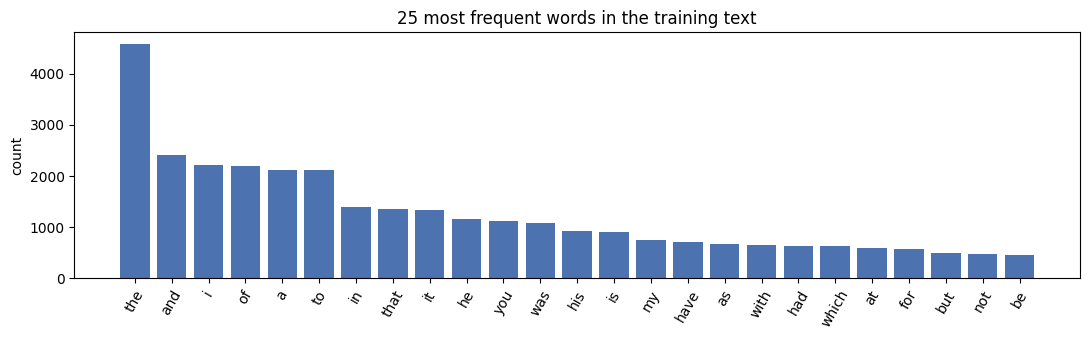

In [8]:
top = vocab.idx2word[2:27]
plt.figure(figsize=(11, 3.5))
plt.bar(top, [vocab.counts[w] for w in top], color="#4C72B0")
plt.xticks(rotation=60); plt.ylabel("count"); plt.title("25 most frequent words in the training text")
plt.tight_layout(); plt.show()

<a id="observations-step-6"></a>
### Observations

- The vocabulary retains 3,898 entries, including padding and unknown tokens, from 7,280 distinct training words. It covers 95.9% of training tokens.
- ?xyzzy? maps to unknown ID 1, while ?my?, ?dear? and ?watson? receive known IDs. The frequency chart is dominated by common words, which provide a useful baseline.


<a id="step7"></a>
## Step 7: Generate training sequences



In [ ]:
show(sequences.make_sequences)
splits = {name: sequences.make_sequences(s, vocab, cfg.context_size)
          for name, s in (("train", train_s), ("val", val_s), ("test", test_s))}
for name, (x, y) in splits.items():
    print(f"{name:5s}: inputs {tuple(x.shape)}, targets {tuple(y.shape)}")

x_train, y_train = splits["train"]
print("\nFirst training examples (input → target):")
for i in range(5, 13):
    print(f"  {' '.join(vocab.decode(x_train[i].tolist())):45s} → {vocab.idx2word[int(y_train[i])]}")

<a id="observations-step-7"></a>
### Observations

- The input arrays contain five word IDs per example. Training, validation and testing produce 79,763, 10,656 and 9,935 examples, respectively.
- Sliding windows pair each context with its following word. Unknown targets are skipped, including 895 test tokens; therefore, these sequence counts exclude words outside the training vocabulary.


<a id="step8"></a>
## Step 8: Convert words to vectors with Word2Vec



In [ ]:
show(embeddings.train_word2vec, embeddings.build_embedding_matrix)
w2v = embeddings.train_word2vec(train_s, cfg.embedding_dim, cfg.w2v_window, cfg.min_freq,
                                cfg.w2v_sg, cfg.w2v_negative, cfg.w2v_epochs, cfg.seed)
embedding_matrix, covered = embeddings.build_embedding_matrix(w2v, vocab, cfg.seed)
print(f"Embedding matrix: {embedding_matrix.shape}  (Word2Vec covers {covered}/{len(vocab) - 2} words)")
print("Vector for 'holmes' (first 8 of 100 numbers):", np.round(w2v.wv["holmes"][:8], 3))
print()
for w in ["holmes", "door", "said", "lady", "money", "night"]:
    print(f"Most similar to {w!r:9s}:", ", ".join(f"{n} ({s:.2f})" for n, s in w2v.wv.most_similar(w, topn=5)))

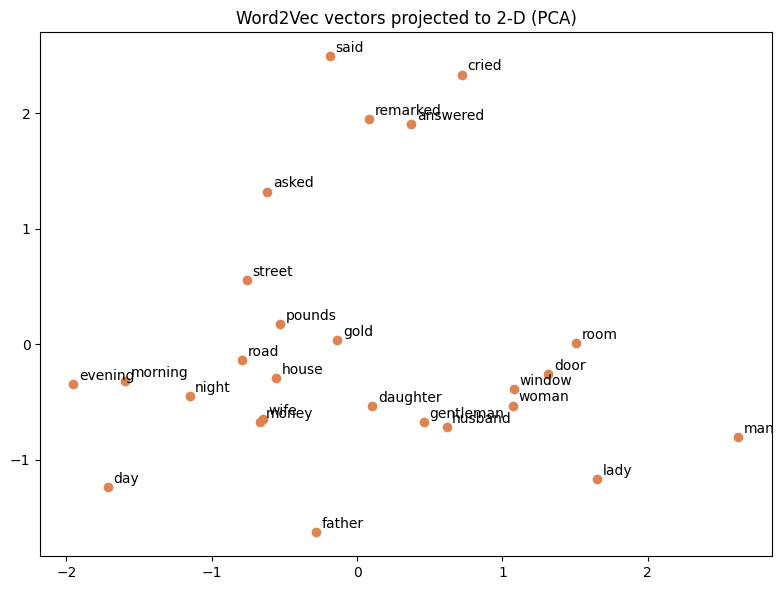

In [11]:
# Project the 100-dimensional vectors to 2-D (PCA) to see how the words are arranged.
words = ["man", "woman", "lady", "gentleman", "father", "daughter", "wife", "husband",
         "door", "window", "room", "house", "street", "road",
         "said", "cried", "asked", "remarked", "answered",
         "morning", "evening", "night", "day", "pounds", "money", "gold"]
words = [w for w in words if w in w2v.wv]
vecs = np.array([w2v.wv[w] for w in words])
vecs = vecs - vecs.mean(axis=0)
_, _, vt = np.linalg.svd(vecs, full_matrices=False)
xy = vecs @ vt[:2].T
plt.figure(figsize=(8, 6))
plt.scatter(xy[:, 0], xy[:, 1], color="#DD8452")
for (px, py), w in zip(xy, words):
    plt.annotate(w, (px, py), xytext=(4, 3), textcoords="offset points")
plt.title("Word2Vec vectors projected to 2-D (PCA)"); plt.tight_layout(); plt.show()

<a id="observations-step-8"></a>
### Observations

- The embedding matrix has 3,898 rows and 100 dimensions; Word2Vec covers all 3,896 ordinary vocabulary words. Padding and unknown entries receive separate initializations.
- ?holmes? neighbors ?sherlock?, while ?lady? neighbors ?neatly?, showing mixed context relationships. The two-dimensional projection compresses the vectors, so visible distances cannot represent all information.


<a id="step9"></a>
## Step 9: Train a neural network

```text
five word ids -> Word2Vec-initialized embedding lookup
             -> two LSTM layers, 256 hidden units each
             -> dropout -> one logit per vocabulary entry
```



In [12]:
show(model_mod.NextWordLSTM)
net = model_mod.NextWordLSTM(embedding_matrix, cfg.hidden_size, cfg.num_layers, cfg.dropout, vocab.pad_id)
print(net)
print(f"Trainable parameters: {sum(p.numel() for p in net.parameters()):,}")

```python
class NextWordLSTM(nn.Module):
    """word ids -> Word2Vec embeddings -> 2-layer LSTM -> scores for every vocabulary word."""

    def __init__(
        self,
        embedding_matrix: np.ndarray,
        hidden_size: int,
        num_layers: int,
        dropout: float,
        pad_id: int = 0,
    ):
        super().__init__()
        vocab_size, embedding_dim = embedding_matrix.shape
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_id)
        self.embedding.weight.data.copy_(torch.from_numpy(embedding_matrix))
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_size, vocab_size)

    def set_embeddings_trainable(self, trainable: bool) -> None:
        self.embedding.weight.requires_grad_(trainable)

    def forward(self, context: torch.Tensor) -> torch.Tensor:
        """context: (batch, context_size) ids -> logits: (batch, vocab_size)."""
        vectors = self.embedding(context)
        outputs, _ = self.lstm(vectors)
        last = outputs[:, -1, :]  # the LSTM's summary after reading the whole context
        return self.output(self.dropout(last))
```

NextWordLSTM(
  (embedding): Embedding(3898, 100, padding_idx=0)
  (lstm): LSTM(100, 256, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (output): Linear(in_features=256, out_features=3898, bias=True)
)
Trainable parameters: 2,284,514


### Training



In [ ]:
show(trainer.train)
loaders = {
    name: DataLoader(sequences.NextWordDataset(x, y), batch_size=cfg.batch_size, shuffle=(name == "train"),
                     generator=torch.Generator().manual_seed(cfg.seed))
    for name, (x, y) in splits.items()
}
history = trainer.train(net, loaders["train"], loaders["val"], device, cfg.epochs, cfg.learning_rate,
                        cfg.weight_decay, cfg.grad_clip, cfg.patience, cfg.freeze_embeddings_epochs)
print(f"Best epoch: {history.best_epoch}")

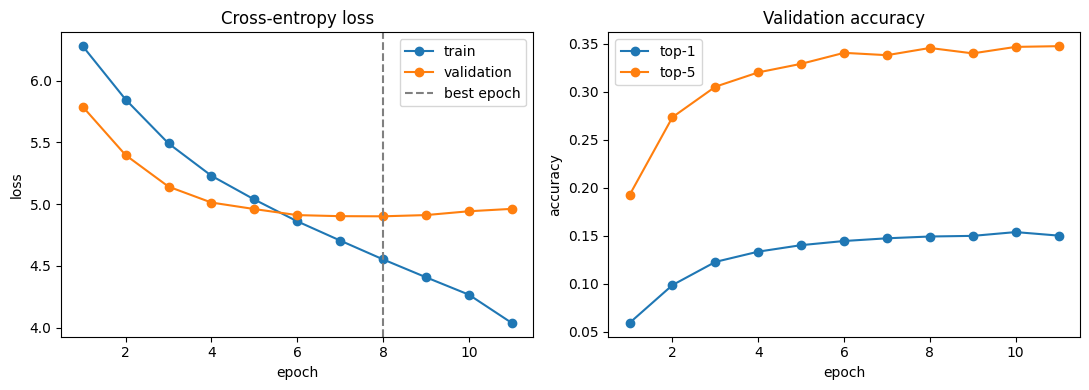

In [14]:
ep = range(1, len(history.train_loss) + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(ep, history.train_loss, "o-", label="train"); a1.plot(ep, history.val_loss, "o-", label="validation")
a1.axvline(history.best_epoch, ls="--", c="gray", label="best epoch")
a1.set(title="Cross-entropy loss", xlabel="epoch", ylabel="loss"); a1.legend()
a2.plot(ep, history.val_top1, "o-", label="top-1"); a2.plot(ep, history.val_top5, "o-", label="top-5")
a2.set(title="Validation accuracy", xlabel="epoch", ylabel="accuracy"); a2.legend()
plt.tight_layout(); plt.show()

<a id="observations-step-9"></a>
### Observations

- The model has 2,284,514 parameters. Training loss falls from 6.279 to 4.038, showing improved fit to training examples.
- Validation loss reaches its minimum, approximately 4.901, at epoch 8, then rises while training loss falls. This pattern suggests overfitting; early stopping ends training at epoch 11 and restores epoch 8.


<a id="evaluation"></a>
## Evaluation on held-out text

Testing uses the final 700 preprocessed segments, containing 10,830 tokens. Only 9,935 known-word targets are scored; 895 unknown targets are excluded. **The usual table therefore covers 91.7% of test tokens.**

- **Top-1 accuracy:** the actual next word is the highest-scoring word.
- **Top-5 accuracy:** the actual next word is among the five highest-scoring words.
- **Perplexity:** `exp(mean cross-entropy)`, using natural logarithms. Lower values mean less uncertainty on the scored targets; this is not a literal count of candidate words.
- **Baseline:** always predicts the most common training target, or the five most common targets.

The model achieved 15.2% top-1 accuracy, 33.9% top-5 accuracy and perplexity 137.8 on the scored subset. Counting excluded words as incorrect exact-word predictions gives **13.9% top-1** and **31.1% top-5** across all 10,830 tokens. That adjustment does not calculate full-test perplexity.

Evaluation uses full model logits. The suggestion interface separately masks special tokens and renormalizes its probabilities. Test results are from one checkpoint on one book, with no estimate of variation across seeds or other domains.


In [ ]:
test = trainer.evaluate(net, loaders["test"], device)
common = [w for w, _ in Counter(y_train.tolist()).most_common(5)]
y_test = splits["test"][1].tolist()
base1 = sum(t == common[0] for t in y_test) / len(y_test)
base5 = sum(t in common for t in y_test) / len(y_test)

n_test_tokens = sum(map(len, test_s))
n_scored = len(y_test)
print(f"Scored targets: {n_scored:,}/{n_test_tokens:,}; excluded unknowns: {n_test_tokens - n_scored:,}")
print("Known-word targets only:")
print(f"Baseline: top-1 {base1:.1%}, top-5 {base5:.1%}")
print(f"LSTM: top-1 {test.top1:.1%}, top-5 {test.top5:.1%}, perplexity {test.perplexity:.1f}")
print(f"Baseline guesses: {vocab.decode(common)}")
print("All tokens, unknowns counted as incorrect:")
print(f"LSTM: top-1 {test.top1 * n_scored / n_test_tokens:.1%}, top-5 {test.top5 * n_scored / n_test_tokens:.1%}")


## Using the model: predict the next word

Typed text uses the same character normalization, lowercasing, punctuation handling and tokenization as the corpus. The last five words become ids, with padding if needed. Softmax converts scores into probabilities after masking `<pad>` and `<unk>`.

Generation appends one word and repeats. Greedy generation chooses the highest-scoring word; temperature sampling draws from a distribution. These demonstrations are not labeled test cases: a prompt can have several reasonable continuations.


In [ ]:
predictor = Predictor(net, vocab, cfg.context_size, device=str(device))
prompts = ["My dear Watson,", "I have no doubt that", "Sherlock Holmes was", "It was a dark",
           "What do you", "I shall be happy to", "There was a knock at the"]
for p in prompts:
    print(f"{p!r:30s} → " + ", ".join(f"{w} ({pr:.0%})" for w, pr in predictor.predict_next(p, 5)))

In [ ]:
for p in ["it was a", "holmes looked at me and"]:
    print("greedy     :", predictor.generate(p, 12))
    print("sampled 0.7:", predictor.generate(p, 12, temperature=0.7, seed=1), "\n")

**Reading the suggestions.** The saved model returns plausible alternatives for some prompts and awkward ones for others. Its greedy output also repeats phrases. These observations describe this checkpoint; they do not prove the cause of its errors. A low probability for the leading word is not, by itself, evidence that the model is poorly calibrated. Likewise, *my dear watson* followed by *i* is not automatically wrong without a reference continuation.


## Save the trained model and matching results

This cell writes the current weights, vocabulary, Word2Vec model, configuration, evaluation metrics, target coverage and training plot to `artifacts/`. Saving metrics with the current model avoids leaving results from a previous run attached to a new checkpoint.

After running it, check the saved files with:

```bash
python -m nwp.verify --output artifacts/verification.json
python -m nwp.predict "my dear" --generate 10
```


In [ ]:
import hashlib
import json
from nwp.pipeline import DEMO_PROMPTS, unigram_baseline

out = cfg.artifacts_dir
out.mkdir(parents=True, exist_ok=True)
torch.save({k: v.cpu() for k, v in net.state_dict().items()}, out / "model.pt")
vocab.save(out / "vocab.json")
w2v.save(str(out / "word2vec.model"))
(out / "config.json").write_text(json.dumps(cfg.to_dict(), indent=2), encoding="utf-8")
report = {
    "dataset": {"kaggle": cfg.kaggle_dataset, "file": cfg.raw_filename,
                "sentences": len(sentences_tok), "tokens": n_tokens,
                "raw_sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest()},
    "vocab_size": len(vocab),
    "sequences": {name: len(x) for name, (x, _) in splits.items()},
    "target_coverage": {
        name: {"tokens": sum(map(len, part)), "scored_targets": len(splits[name][1]),
               "excluded_unknown_targets": sum(map(len, part)) - len(splits[name][1])}
        for name, part in (("train", train_s), ("val", val_s), ("test", test_s))
    },
    "word2vec_coverage": covered,
    "word2vec_neighbours": {w: [n for n, _ in w2v.wv.most_similar(w, topn=5)]
                           for w in ("holmes", "watson", "door", "said", "money") if w in w2v.wv},
    "history": history.__dict__,
    "test": test.as_dict(),
    "baseline": unigram_baseline(splits["train"][1], splits["test"][1]),
    "demo_predictions": {p: predictor.predict_next(p, 5) for p in DEMO_PROMPTS},
}
(out / "metrics.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
fig.savefig(out / "training_curves.png", dpi=120)
print("Saved current model, matching metrics, target coverage and training plot to", out)


## Summary of the pipeline

| Step | What the code does |
|---|---|
| Collect | Downloads and caches a text file from the configured Kaggle dataset. |
| Clean | Removes outer Gutenberg boilerplate, normalizes characters and splits segments. |
| Lowercase | Merges capitalization variants. |
| Remove punctuation | Removes punctuation except apostrophes inside words. |
| Tokenize | Splits text into word lists. |
| Vocabulary | Assigns ids to training words seen at least twice, plus special tokens. |
| Sequences | Uses five context words to predict the next known word. |
| Word2Vec | Learns 100-dimensional skip-gram vectors from training segments. |
| Neural network | Trains embedding, LSTM and linear layers using cross-entropy and AdamW. |

Each required step has code and an explanation.


<a id="insights"></a>
## Final Insights and Recommendations

**Final insights**

1. **Context improved prediction by a measurable margin.** On 9,935 known-word test targets, the model achieved 15.2% top-1 and 33.9% top-5 accuracy, compared with 5.3% and 16.8% for the common-word baseline. The gains of 9.9 and 17.1 percentage points show that the complete system learned useful context patterns.
2. **Epoch 8 provided the best validation fit.** Between epochs 8 and 11, training loss fell from 4.552 to 4.038 while validation loss rose from 4.901 to 4.961. This divergence is consistent with overfitting and supports retaining the epoch-8 checkpoint rather than the final weights.
3. **Unknown-word handling materially affects reported accuracy.** The evaluation excludes 895 of 10,830 test tokens, or 8.3%. Counting those tokens as incorrect lowers top-1 accuracy to 13.9% and top-5 accuracy to 31.1%. Perplexity 137.8 describes only the known-target subset, so it cannot summarize performance on every original test word.
4. **Embedding coverage is complete, but the neighbors show mixed relationships.** Word2Vec provides vectors for all 3,896 ordinary vocabulary words. Pairs such as *holmes* with *sherlock* are intuitive, whereas *watson* with *index* is less so. Complete vector coverage alone does not establish embedding quality or Word2Vec's contribution to prediction accuracy.
5. **Next-word accuracy and generation quality reveal different limitations.** For *what do you*, the model suggests *see, mean, do, have,* and *know*. Yet greedy generation repeats *and i have heard* in the displayed sample. The accuracy gains therefore need to be assessed alongside repetition and fluency when judging generated text.
6. **The findings are specific to one book and one run.** The model has 2,284,514 parameters and uses 83,147 training tokens. These counts describe the experiment's scale, but they do not establish the cause of overfitting. Performance across training seeds, other authors and other writing styles remains unmeasured.

**Recommendations**

The following experiments address these findings; their benefits still need to be measured.

1. **Prioritize coverage in the next evaluation.** Keep the original word sequence and split boundaries fixed, and compare vocabulary thresholds of one and two occurrences. Report excluded targets, known-target accuracy and full-token exact-word accuracy together. This directly addresses the 895 test words omitted from the current scores.
2. **Optimize validation performance rather than extending training.** Preserve early stopping and selection by validation loss. Compare the current 256-unit LSTM with smaller hidden sizes and alternative regularization settings. The rise in validation loss after epoch 8 makes these controlled comparisons more informative than simply adding epochs.
3. **Measure Word2Vec's contribution directly.** Compare randomly initialized embeddings, frozen Word2Vec embeddings and fine-tuned Word2Vec embeddings using the same splits, architecture, training budget and seeds. The baseline comparison measures the complete system; this experiment would show whether learned word vectors improve next-word prediction under comparable conditions.
4. **Test data expansion and cleaning separately.** Compare several training-corpus sizes while keeping the held-out evaluation text fixed. In a separate comparison, remove remaining title-page, credit and contents material before retraining. Measuring each change separately would show whether additional text or cleaner input improves validation performance.
5. **Evaluate decoding against the observed repetition.** Generate equal-length continuations for the same prompts using greedy decoding and temperature sampling, including the existing temperature of 0.7. Compare repeated phrase counts and assess grammatical coherence. This would test whether sampling reduces loops while preserving readable continuations.
6. **Measure stability before making broader performance claims.** Repeat training with several fixed seeds and report mean accuracy with its variation. Then evaluate the selected configuration on text from another author without tuning on that test set. This would assess whether the observed gains extend beyond one run and one book.


<a id="conclusion"></a>
## Conclusion

This project implements a complete next-word prediction pipeline: collecting a dataset, cleaning and lowercasing the text, removing punctuation with a stated apostrophe exception, tokenizing, building a vocabulary, creating training sequences, learning Word2Vec vectors, and training an LSTM neural network. The code and pseudocode show how these steps connect, and the explanations describe their purpose in plain English.

The saved checkpoint achieved 15.2% top-1 accuracy, 33.9% top-5 accuracy and perplexity 137.8 on known-word test targets, exceeding the common-word baseline on that subset. Because 895 unknown targets were excluded, these figures do not describe every test token. Counting the excluded targets as incorrect gives 13.9% top-1 and 31.1% top-5 accuracy across the full test stream.

The results demonstrate that this implementation can learn useful context patterns, while the loss curves and generated samples show limitations in generalization and repetition. Further comparisons are needed to measure Word2Vec's contribution and identify which changes improve performance.
